In [13]:
# ===============================
# IMPORT LIBRARY
# ===============================
import tensorflow as tf
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D, MaxPooling2D, Flatten,
    Dense, Dropout, GlobalAveragePooling2D, BatchNormalization
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2, ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.preprocessing import image
from tensorflow.keras.models import load_model
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import os


In [3]:
# ===============================
# CONFIG
# ===============================
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 100
NUM_CLASSES = 10

TRAIN_DIR = r"C:\Users\acer\Downloads\CNN PROJECT\CNN SAMPAH\dataset\train"
VAL_DIR   = r"C:\Users\acer\Downloads\CNN PROJECT\CNN SAMPAH\dataset\validation"
TEST_DIR  = r"C:\Users\acer\Downloads\CNN PROJECT\CNN SAMPAH\dataset\test"

In [4]:
# ===============================
# DATA GENERATOR
# ===============================
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True
)

val_test_datagen = ImageDataGenerator(rescale=1./255)

train_data = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

val_data = val_test_datagen.flow_from_directory(
    VAL_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

test_data = val_test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

class_names = list(train_data.class_indices.keys())

Found 480 images belonging to 10 classes.
Found 480 images belonging to 10 classes.
Found 480 images belonging to 10 classes.


In [ ]:
# ===============================
# MODEL 1 
# ===============================
model_1 = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(224,224,3)),
    MaxPooling2D(2,2),

    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D(2,2),

    Conv2D(128, (3,3), activation='relu'),
    MaxPooling2D(2,2),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(NUM_CLASSES, activation='softmax')
])

model_1.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model_1.summary()

history_1 = model_1.fit(
    train_data,
    validation_data=val_data,
    epochs=EPOCHS
)

c:\Users\acer\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,170,250 (42.61 MB)

 Trainable params: 11,170,250 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 16s 900ms/step - accuracy: 0.0938 - loss: 2.7825 - val_accuracy: 0.1063 - val_loss: 2.2830
Epoch 2/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 12s 833ms/step - accuracy: 0.1458 - loss: 2.2750 - val_accuracy: 0.1792 - val_loss: 2.2325
Epoch 3/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 13s 863ms/step - accuracy: 0.1521 - loss: 2.2737 - val_accuracy: 0.1646 - val_loss: 2.2222
Epoch 4/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 13s 868ms/step - accuracy: 0.2083 - loss: 2.2137 - val_accuracy: 0.1958 - val_loss: 2.1046
Epoch 5/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 13s 904ms/step - accuracy: 0.2417 - loss: 2.1302 - val_accuracy: 0.3042 - val_loss: 2.0217
Epoch 6/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 13s 835ms/step - accuracy: 0.2250 - loss: 2.1042 - val_accuracy: 0.3625 - val_loss: 1.8945
Epoch 7/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 12s 814ms/step - accuracy: 0.3063 - loss: 2.0061 - val_accuracy: 0.3875 - val_loss: 1.8093
Epoch 8/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 12s 817ms/step - accuracy: 0.3042 - loss: 1.9642 - 

In [19]:
print("\nEvaluasi Model 1 CNN:")
mod1_loss, mod1_acc = model_1.evaluate(test_data)


Evaluasi Model 1 CNN:
15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 174ms/step - accuracy: 0.9958 - loss: 0.0349


In [20]:
model_1.save("model_1_cnn_sampah.h5")
print("Model berhasil disimpan dalam format .h5")

Model berhasil disimpan dalam format .h5


In [5]:
# ===============================
# MODEL 2: MobileNetV2
# ===============================
base_mobilenet = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(224,224,3)
)
base_mobilenet.trainable = False

model_mobilenet = Sequential([
    base_mobilenet,
    GlobalAveragePooling2D(),
    Dense(128, activation='relu'),
    Dense(NUM_CLASSES, activation='softmax')
])

model_mobilenet.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model_mobilenet.summary()

print("Training MobileNetV2...")
history_mobilenet = model_mobilenet.fit(
    train_data,
    validation_data=val_data,
    epochs=EPOCHS
)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,423,242 (9.24 MB)

 Trainable params: 165,258 (645.54 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Training MobileNetV2...
Epoch 1/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 20s 1s/step - accuracy: 0.3896 - loss: 1.8839 - val_accuracy: 0.7312 - val_loss: 0.9446
Epoch 2/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 14s 976ms/step - accuracy: 0.7583 - loss: 0.7836 - val_accuracy: 0.8500 - val_loss: 0.4660
Epoch 3/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 14s 992ms/step - accuracy: 0.8542 - loss: 0.4930 - val_accuracy: 0.8896 - val_loss: 0.3266
Epoch 4/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 14s 963ms/step - accuracy: 0.9042 - loss: 0.2946 - val_accuracy: 0.9625 - val_loss: 0.1750
Epoch 5/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 14s 963ms/step - accuracy: 0.9521 - loss: 0.1843 - val_accuracy: 0.9750 - val_loss: 0.1384
Epoch 6/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step - accuracy: 0.9521 - loss: 0.1750 - val_accuracy: 0.9833 - val_loss: 0.1002
Epoch 7/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 14s 941ms/step - accuracy: 0.9771 - loss: 0.1140 - val_accuracy: 0.9937 - val_loss: 0.0685
Epoch 8/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 15s 998ms/step - accuracy: 0.9812

In [ ]:
print("\nEvaluasi Model 2 MobileNet:")
mod2_loss, mod2_acc = model_mobilenet.evaluate(test_data)


Evaluasi Model 2 CNN:
15/15 ━━━━━━━━━━━━━━━━━━━━ 7s 425ms/step - accuracy: 1.0000 - loss: 0.0044


In [9]:
model_mobilenet.save("mobilenet_sampah.h5")
print("Model berhasil disimpan dalam format .h5")

Model berhasil disimpan dalam format .h5


In [14]:
# ===============================
# MODEL 3 ResNet50
# ===============================

base_resnet = ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze sebagian besar layer
for layer in base_resnet.layers[:-30]:
    layer.trainable = False

# Fine-tune 30 layer terakhir
for layer in base_resnet.layers[-30:]:
    layer.trainable = True
    
model_resnet = Sequential([
    base_resnet,
    GlobalAveragePooling2D(),

    BatchNormalization(),
    Dense(256, activation='relu'),
    Dropout(0.5),

    Dense(train_data.num_classes, activation='softmax')
])

model_resnet.compile(
    optimizer=Adam(learning_rate=1e-4),  # naikkan LR agar learning efektif
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model_resnet.summary()

from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

callbacks = [
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.3,
        patience=5,
        min_lr=1e-6,
        verbose=1
    ),
    EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True,
        verbose=1
    )
]

print("Training ResNet50 ...")
history_resnet = model_resnet.fit(
    train_data,
    validation_data=val_data,
    epochs=EPOCHS,
    callbacks=callbacks

)

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 2048)           │         8,192 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,123,018 (92.02 MB)

 Trainable params: 14,981,386 (57.15 MB)

 Non-trainable params: 9,141,632 (34.87 MB)

Training ResNet50 ...
Epoch 1/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 54s 3s/step - accuracy: 0.1646 - loss: 3.1802 - val_accuracy: 0.1000 - val_loss: 2.4957 - learning_rate: 1.0000e-04
Epoch 2/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 35s 2s/step - accuracy: 0.2333 - loss: 2.5446 - val_accuracy: 0.1000 - val_loss: 2.5077 - learning_rate: 1.0000e-04
Epoch 3/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 35s 2s/step - accuracy: 0.2750 - loss: 2.3278 - val_accuracy: 0.1000 - val_loss: 2.5186 - learning_rate: 1.0000e-04
Epoch 4/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 39s 3s/step - accuracy: 0.2937 - loss: 2.2679 - val_accuracy: 0.1000 - val_loss: 2.4818 - learning_rate: 1.0000e-04
Epoch 5/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 35s 2s/step - accuracy: 0.3458 - loss: 2.0034 - val_accuracy: 0.1042 - val_loss: 2.4077 - learning_rate: 1.0000e-04
Epoch 6/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 36s 2s/step - accuracy: 0.3646 - loss: 1.9696 - val_accuracy: 0.1688 - val_loss: 2.3110 - learning_rate: 1.0000e-04
Epoch 7/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 35s 2s/st

In [15]:
print("\nEvaluasi Model 3 ResNet50:")
mod3_loss, mod3_acc = model_resnet.evaluate(test_data)


Evaluasi Model 3 ResNet50:
15/15 ━━━━━━━━━━━━━━━━━━━━ 17s 1s/step - accuracy: 0.9688 - loss: 0.1500


In [16]:
model_resnet.save("resnet50_sampah.h5")
print("Model berhasil disimpan dalam format .h5")

Model berhasil disimpan dalam format .h5


15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 200ms/step


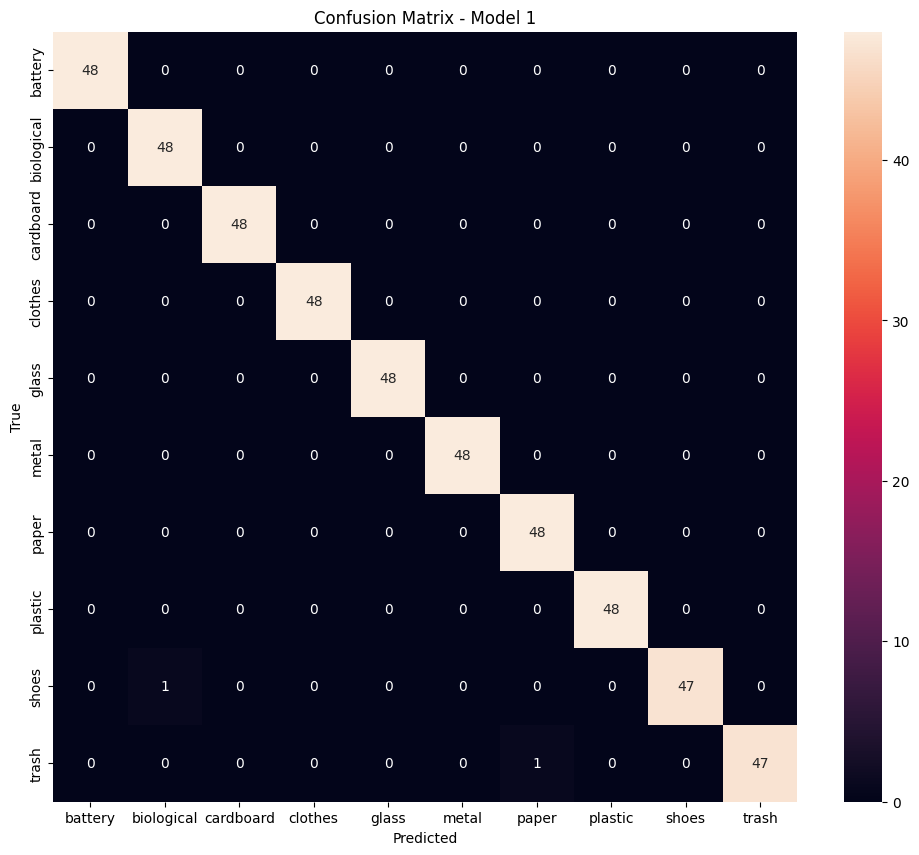

              precision    recall  f1-score   support

     battery       1.00      1.00      1.00        48
  biological       0.98      1.00      0.99        48
   cardboard       1.00      1.00      1.00        48
     clothes       1.00      1.00      1.00        48
       glass       1.00      1.00      1.00        48
       metal       1.00      1.00      1.00        48
       paper       0.98      1.00      0.99        48
     plastic       1.00      1.00      1.00        48
       shoes       1.00      0.98      0.99        48
       trash       1.00      0.98      0.99        48

    accuracy                           1.00       480
   macro avg       1.00      1.00      1.00       480
weighted avg       1.00      1.00      1.00       480



In [21]:
# ===============================
# CONFUSION MATRIX (model 1)
# ===============================
y_true = test_data.classes
y_pred = np.argmax(model_1.predict(test_data), axis=1)

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(12,10))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix - Model 1")
plt.show()

print(classification_report(y_true, y_pred, target_names=class_names))

15/15 ━━━━━━━━━━━━━━━━━━━━ 8s 415ms/step


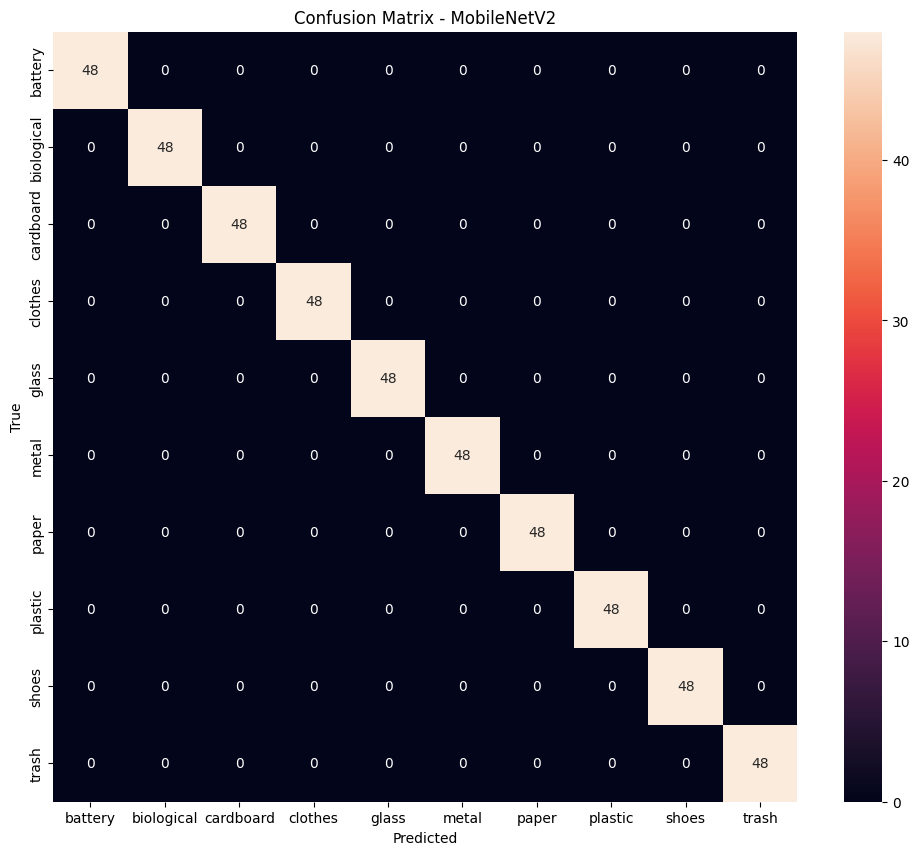

              precision    recall  f1-score   support

     battery       1.00      1.00      1.00        48
  biological       1.00      1.00      1.00        48
   cardboard       1.00      1.00      1.00        48
     clothes       1.00      1.00      1.00        48
       glass       1.00      1.00      1.00        48
       metal       1.00      1.00      1.00        48
       paper       1.00      1.00      1.00        48
     plastic       1.00      1.00      1.00        48
       shoes       1.00      1.00      1.00        48
       trash       1.00      1.00      1.00        48

    accuracy                           1.00       480
   macro avg       1.00      1.00      1.00       480
weighted avg       1.00      1.00      1.00       480



In [22]:
# ===============================
# CONFUSION MATRIX (MobileNetV2)
# ===============================
y_true = test_data.classes
y_pred = np.argmax(model_mobilenet.predict(test_data), axis=1)

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(12,10))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix - MobileNetV2")
plt.show()

print(classification_report(y_true, y_pred, target_names=class_names))

15/15 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step


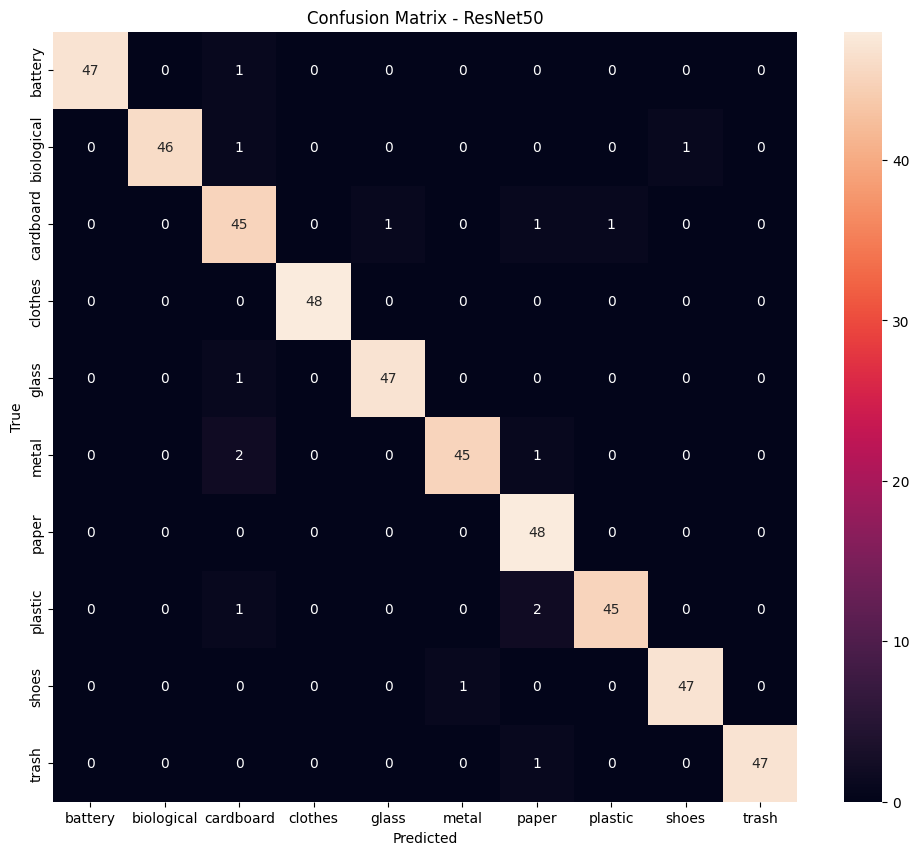

              precision    recall  f1-score   support

     battery       1.00      0.98      0.99        48
  biological       1.00      0.96      0.98        48
   cardboard       0.88      0.94      0.91        48
     clothes       1.00      1.00      1.00        48
       glass       0.98      0.98      0.98        48
       metal       0.98      0.94      0.96        48
       paper       0.91      1.00      0.95        48
     plastic       0.98      0.94      0.96        48
       shoes       0.98      0.98      0.98        48
       trash       1.00      0.98      0.99        48

    accuracy                           0.97       480
   macro avg       0.97      0.97      0.97       480
weighted avg       0.97      0.97      0.97       480



In [23]:
# ===============================
# CONFUSION MATRIX (RESNET)
# ===============================
y_true = test_data.classes
y_pred = np.argmax(model_resnet.predict(test_data), axis=1)

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(12,10))
sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=class_names,
            yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix - ResNet50")
plt.show()

print(classification_report(y_true, y_pred, target_names=class_names))


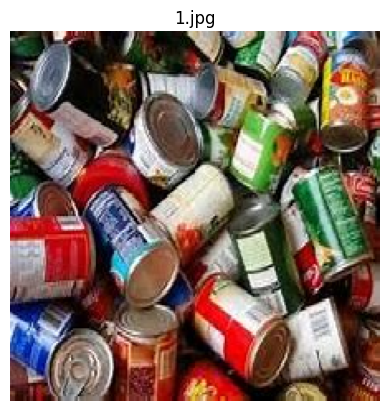

Hasil Prediksi:
CNN        → biological (93.18%)
MobileNet  → metal (97.60%)
ResNet50   → biological (54.16%)


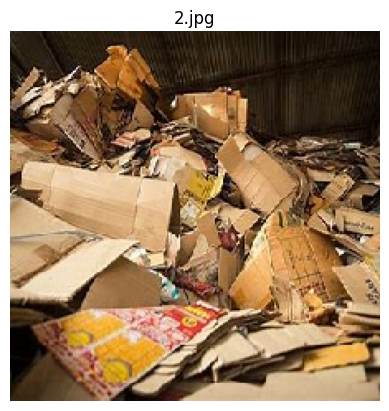

Hasil Prediksi:
CNN        → biological (97.88%)
MobileNet  → cardboard (100.00%)
ResNet50   → metal (86.94%)


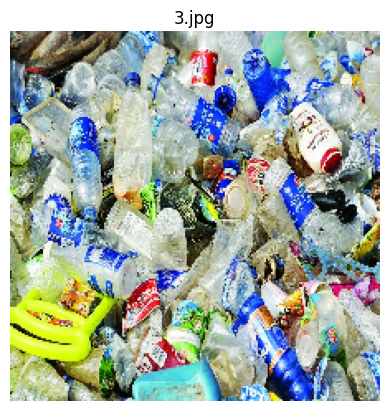

Hasil Prediksi:
CNN        → glass (52.36%)
MobileNet  → plastic (98.43%)
ResNet50   → biological (52.37%)


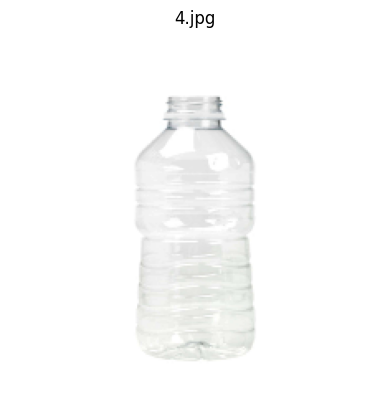

Hasil Prediksi:
CNN        → trash (97.93%)
MobileNet  → trash (92.31%)
ResNet50   → trash (91.73%)


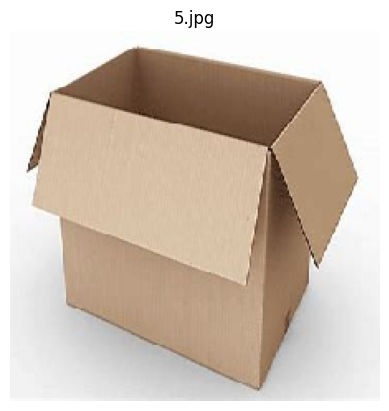

Hasil Prediksi:
CNN        → biological (50.60%)
MobileNet  → cardboard (99.94%)
ResNet50   → paper (36.45%)


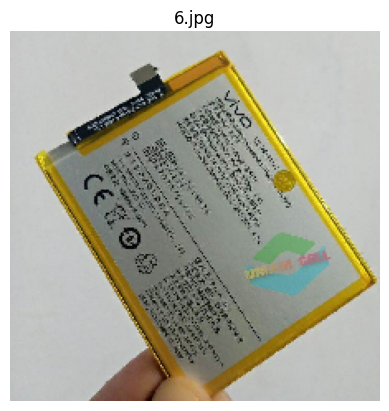

Hasil Prediksi:
CNN        → cardboard (56.84%)
MobileNet  → paper (78.76%)
ResNet50   → paper (59.76%)


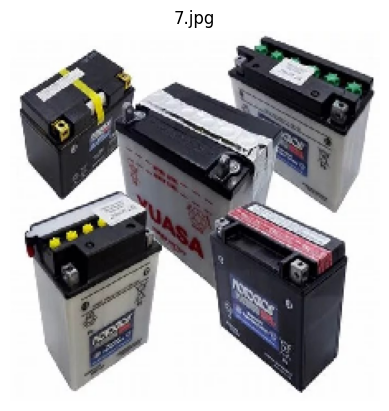

Hasil Prediksi:
CNN        → shoes (95.62%)
MobileNet  → battery (98.07%)
ResNet50   → battery (99.64%)


In [28]:
# ===== LOAD MODELS =====
model_1 = load_model("model_1_cnn_sampah.h5")
model_mobilenet = load_model("mobilenet_sampah.h5")
model_resnet = load_model("resnet50_sampah.h5")

models = {
    "CNN": model_1,
    "MobileNet": model_mobilenet,
    "ResNet50": model_resnet
}

# ===== CLASS NAMES =====
class_names = [
    "battery",
    "biological",
    "cardboard",
    "clothes",
    "glass",
    "metal",
    "paper",
    "plastic",
    "shoes",
    "trash"
]

# ===== FUNCTION =====
def predict_with_all_models(image_path, models, class_names):
    img = image.load_img(image_path, target_size=(224, 224))
    img_array = image.img_to_array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    # tampilkan gambar
    plt.imshow(img)
    plt.axis("off")
    plt.title(os.path.basename(image_path))
    plt.show()

    print("Hasil Prediksi:")
    for name, model in models.items():
        pred = model.predict(img_array, verbose=0)
        class_idx = np.argmax(pred)
        confidence = np.max(pred) * 100

        print(f"{name:10s} → {class_names[class_idx]} ({confidence:.2f}%)")

# ===== PREDICT SEMUA GAMBAR DALAM FOLDER =====
test_folder = r"C:\Users\acer\Downloads\CNN PROJECT\CNN SAMPAH\sampahtes"

for img_name in os.listdir(test_folder):
    if img_name.lower().endswith((".jpg", ".jpeg", ".png")):
        img_path = os.path.join(test_folder, img_name)

        print("="*60)
        predict_with_all_models(img_path, models, class_names)